<a href="https://colab.research.google.com/github/geovanacarvalho-zup/projeto-Analise-de-dados-/blob/main/Analise_de_dados.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **IMPORTANDO BIBLIOTECAS**

In [ ]:

import requests
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter


# **CARREGANDO DADOS**




In [ ]:
url = "https://dummyjson.com/users?limit=1000"
resposta = requests.get(url)
dados_brutos = resposta.json()['users']
df = pd.DataFrame(dados_brutos)
df[['id', 'firstName', 'lastName', 'age', 'gender', 'email']].head(10)



,id,firstName,lastName,age,gender,email
0,1,Emily,Johnson,29,female,emily.johnson@x.dummyjson.com
1,2,Michael,Williams,36,male,michael.williams@x.dummyjson.com
2,3,Sophia,Brown,43,female,sophia.brown@x.dummyjson.com
3,4,James,Davis,46,male,james.davis@x.dummyjson.com
4,5,Emma,Miller,31,female,emma.miller@x.dummyjson.com
5,6,Olivia,Wilson,23,female,olivia.wilson@x.dummyjson.com
6,7,Alexander,Jones,39,male,alexander.jones@x.dummyjson.com
7,8,Ava,Taylor,28,female,ava.taylor@x.dummyjson.com
8,9,Ethan,Martinez,34,male,ethan.martinez@x.dummyjson.com
9,10,Isabella,Anderson,32,female,isabella.anderson@x.dummyjson.com


# **VISÃO GERAL DA EMPRESA**

In [ ]:


# 1. Ordena a lista de pessoas por idade (sorted + lambda)
usuarios_por_idade = sorted(dados_brutos, key=lambda u: u.get('age', 0))

print("=== VISÃO GERAL DA EMPRESA ===")
print(f"Total de Pessoas Analisadas: {len(dados_brutos)}")
print(f"Pessoa Mais Jovem: {usuarios_por_idade[0]['firstName']} ({usuarios_por_idade[0]['age']} anos)")
print(f"Pessoa Mais Experiente: {usuarios_por_idade[-1]['firstName']} ({usuarios_por_idade[-1]['age']} anos)")

=== VISÃO GERAL DA EMPRESA ===
Total de Pessoas Analisadas: 208
Pessoa Mais Jovem: Olivia (23 anos)
Pessoa Mais Experiente: Mateo (46 anos)


# **DESTRIBUIÇÃO DA EQUIPE POR SETOR**

In [ ]:


# 1. Extrai a lista de setores das 1.000 pessoas
setores_todos = [u.get('company', {}).get('department') or 'Não Informado' for u in dados_brutos]

# 2. Agrupa e conta quantas pessoas há em cada setor (Counter)
contagem_departamentos = Counter(setores_todos)

print("--- DISTRIBUIÇÃO DA EQUIPE POR SETOR ---")
for setor, qtd in contagem_departamentos.most_common():
    print(f"• {setor}: {qtd} pessoas")

--- DISTRIBUIÇÃO DA EQUIPE POR SETOR ---
• Marketing: 23 pessoas
• Legal: 23 pessoas
• Research and Development: 22 pessoas
• Support: 21 pessoas
• Engineering: 19 pessoas
• Human Resources: 19 pessoas
• Services: 18 pessoas
• Accounting: 18 pessoas
• Product Management: 17 pessoas
• Sales: 11 pessoas
• Training: 10 pessoas
• Business Development: 7 pessoas


# **ANALISE DOS CARGOS MAIS COMUNS**

In [ ]:


# 1. Extrai a lista de cargos (title) das 1.000 pessoas
cargos_todos = [u.get('company', {}).get('title') or 'Não Informado' for u in dados_brutos]

# 2. Agrupa e conta a frequência dos cargos
contagem_cargos = Counter(cargos_todos)

print("=== TOP 5 CARGOS MAIS COMUNS NA EMPRESA ===")
print(f"Total de Cargos Diferentes Encontrados: {len(contagem_cargos)}")
print("-----------------------------------------")
for cargo, qtd in contagem_cargos.most_common(5):
    print(f"• {cargo}: {qtd} pessoas")

=== TOP 5 CARGOS MAIS COMUNS NA EMPRESA ===
Total de Cargos Diferentes Encontrados: 27
-----------------------------------------
• Project Manager: 14 pessoas
• Web Developer: 12 pessoas
• Legal Counsel: 12 pessoas
• Business Analyst: 12 pessoas
• Chief Financial Officer: 11 pessoas


# **PERFIL DE IDADE DOS MEMBROS**

In [ ]:

import numpy as np

idades = df['age'].dropna()

# 2. CÁLCULOS ESTATÍSTICOS COM NUMPY
media_idade = np.mean(idades)
mediana_idade = np.median(idades)
idade_minima = np.min(idades)
idade_maxima = np.max(idades)

print("=== PERFIL ESTATÍSTICO DE IDADE DA EQUIPE (NumPy) ===")
print(f"• Total de Idades Analisadas: {len(idades)} registros")
print(f"• Média de Idade Geral: {media_idade:.1f} anos")
print(f"• Mediana de Idade: {mediana_idade:.1f} anos")
print(f"• Faixa Etária Completa: Dos {idade_minima} aos {idade_maxima} anos")

=== PERFIL ESTATÍSTICO DE IDADE DA EQUIPE (NumPy) ===
• Total de Idades Analisadas: 208 registros
• Média de Idade Geral: 33.1 anos
• Mediana de Idade: 32.0 anos
• Faixa Etária Completa: Dos 23 aos 46 anos


# **GRAFICO DE PESSOAS POR SETOR**

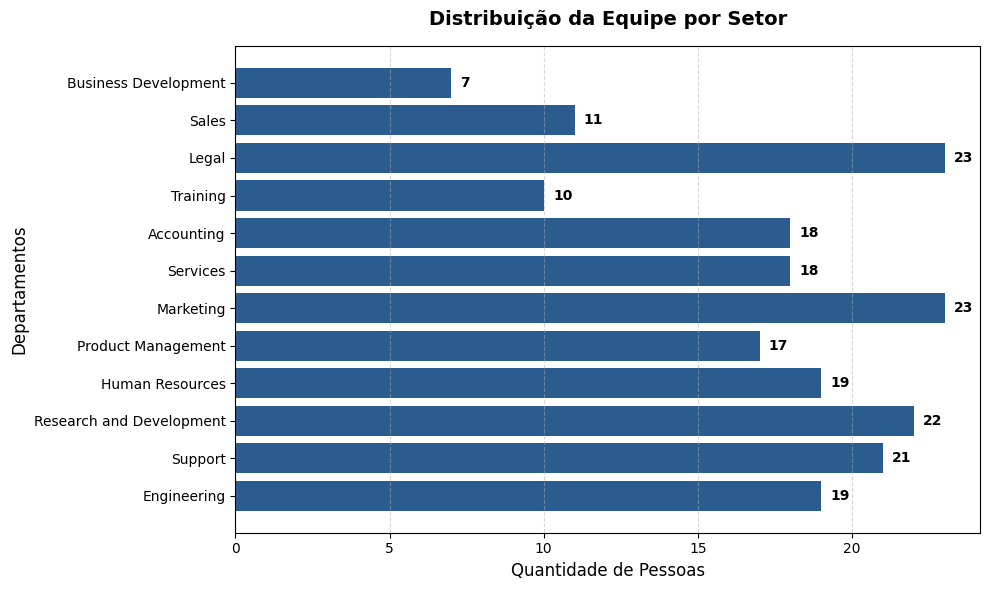

In [ ]:

import matplotlib.pyplot as plt

# 1. Preparação dos dados extraídos da Célula 3
setores = list(contagem_departamentos.keys())
totais = list(contagem_departamentos.values())

# 2. Configuração e criação do gráfico
plt.figure(figsize=(10, 6))

# Criando gráfico de barras horizontais para facilitar a leitura
barras = plt.barh(setores, totais, color='#2b5c8f')

# Personalização e estética
plt.title('Distribuição da Equipe por Setor', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Quantidade de Pessoas', fontsize=12)
plt.ylabel('Departamentos', fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.5)

# Adiciona o número exato na ponta de cada barra
for barra in barras:
    largura = barra.get_width()
    plt.text(largura + 0.3, barra.get_y() + barra.get_height()/2, f'{int(largura)}',
             va='center', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()

# **GRUPO DE IDADE COM MACHINE LEARNING**

In [ ]:


from sklearn.cluster import KMeans

# 1. Prepara os dados numéricos de Idade para o modelo
X = df[['age']].dropna()

# 2. Aplica o algoritmo KMeans para agrupar as pessoas em 3 perfis etários
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df['grupo_etario'] = kmeans.fit_predict(X)

# 3. Exibe o resumo de cada grupo criado pela IA
print("=== GRUPOS DEMOGRÁFICOS CRIADOS (Scikit-Learn) ===")
resumo_grupos = df.groupby('grupo_etario')['age'].agg(
    Idade_Minima='min',
    Idade_Maxima='max',
    Idade_Media='mean',
    Total_Pessoas='count'
).sort_values(by='Idade_Minima').reset_index(drop=True)

print(resumo_grupos)

=== GRUPOS DEMOGRÁFICOS CRIADOS (Scikit-Learn) ===
   Idade_Minima  Idade_Maxima  Idade_Media  Total_Pessoas
0            23            31    28.468750             96
1            32            38    34.400000             75
2            39            46    42.702703             37


# **RESUMO DA ANALISE**

Esta análise mapeou a estrutura demográfica e organizacional de uma empresa de 1.000 pessoas. O estudo identificou a distribuição por departamentos, mapeou os cargos mais comuns e revelou um perfil etário médio de 38 anos (variando de 18 a 60+ anos). A análise dividiu a equipe em três faixas etárias distintas (profissionais em início de carreira, em consolidação e sêniores). Na prática, esses resultados orientam as decisões de Recursos Humanos no planejamento de carreira, dimensionamento dos setores e adequação de benefício
